# Group 5.7 — SmallMLP Depth Ablation Below 500 Samples

Compare **2, 3, 4, and 5 hidden layers** using the installed SmallMLP training procedure. Track test **MAE** for regression and **accuracy** for classification. A positive paired degradation indicates worse performance than depth 2; improvements are retained.

Run all cells with installed `smallmlp`, `torch`, `numpy`, `scipy`, `scikit-learn`, `joblib`, `threadpoolctl`, and `matplotlib`. Outputs go to `results/group57/`. No downloads, installation, or embedded library sources.

In [1]:
import csv
import hashlib
import inspect
import json
import platform
import time
from contextlib import contextmanager
from datetime import datetime, timezone
from importlib import import_module
from importlib.metadata import version
from pathlib import Path
from unittest.mock import patch

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import t
from sklearn.metrics import mean_absolute_error, accuracy_score, roc_auc_score
from joblib import Parallel, delayed, parallel_config, cpu_count
from threadpoolctl import threadpool_limits
from smallmlp import SmallMLPRegressor, SmallMLPClassifier

## 1. Prespecified protocol

Two synthetic tasks, ten independent seeds, supplied training budgets $n\in\{100,200,400\}$, and 5,000 independent test rows per task/seed. Training subsets are nested across sizes; every depth gets identical data and the same native early-stopping split. The test set is never used for fitting or architecture selection.

Keep installed training defaults: up to 500 epochs, patience 30, learning rate 0.001, adaptive dropout and weight decay. The default 20% validation subset is included in $n$: weight updates use 80/160/320 rows. Native preprocessing uses all supplied rows before this internal split; this behavior is preserved. External test rows remain untouched.

Parallelism uses isolated CPU processes and one numerical thread per worker, avoiding shared PyTorch random state and simultaneous backbone patches.

In [2]:
TRAIN_SIZES = (100, 200, 400)
DEPTHS = (2, 3, 4, 5)
SEEDS = (11, 29, 47, 71, 101, 131, 173, 211, 257, 307)
TASKS = ("Friedman regression", "Nonlinear classification")
N_TEST, D = 5000, 10
N_WORKERS = min(4, max(1, cpu_count()-1))
MAX_EPOCHS, PATIENCE = 500, 30

assert all(0 < n < 500 for n in TRAIN_SIZES)
assert tuple(sorted(TRAIN_SIZES)) == TRAIN_SIZES
assert DEPTHS[0] == 2 and len(set(SEEDS)) == len(SEEDS) and len(SEEDS) >= 2
OUT = Path("results/group57") / datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S-%f")
OUT.mkdir(parents=True, exist_ok=False)
(OUT / "trials").mkdir()


def make_estimator(task, seed, max_epochs=MAX_EPOCHS):
    cls = SmallMLPRegressor if task == TASKS[0] else SmallMLPClassifier
    return cls(random_state=seed, max_epochs=max_epochs, patience=PATIENCE)


def portable(value):
    if isinstance(value, dict):
        return {str(k): portable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [portable(v) for v in value]
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return str(value)
    return value


def save_json(path, value):
    Path(path).write_text(json.dumps(portable(value), indent=2, allow_nan=False), encoding="utf-8")


def write_csv(path, rows):
    if not rows:
        return
    with Path(path).open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)

modules = ("smallmlp.nn.backbone", "smallmlp.nn.regressor", "smallmlp.nn.classifier")
source_hashes = {name: hashlib.sha256(Path(inspect.getfile(import_module(name))).read_bytes()).hexdigest()
                 for name in modules}
assert inspect.signature(import_module(modules[0])._Backbone).parameters["n_layers"].default == 2
protocol = dict(train_sizes=TRAIN_SIZES, depths=DEPTHS, seeds=SEEDS, tasks=TASKS, n_test=N_TEST, d=D,
                workers=N_WORKERS, numerical_threads_per_worker=1, device="CPU",
                models={task: make_estimator(task, SEEDS[0]).get_params() for task in TASKS},
                versions={name: version(name) for name in
                          ("smallmlp", "torch", "numpy", "scipy", "scikit-learn", "joblib", "threadpoolctl", "matplotlib")},
                python=platform.python_version(), platform=platform.platform(), source_sha256=source_hashes,
                intervention="native _Backbone n_layers only; regressor/classifier fit methods unchanged",
                primary_metrics={TASKS[0]: "MAE", TASKS[1]: "accuracy"},
                intervals="Pointwise 95% t intervals across independent seeds; paired depth contrasts")
save_json(OUT / "protocol.json", protocol)
print(f"Planned benchmark fits: {len(TASKS)*len(SEEDS)*len(TRAIN_SIZES)*len(DEPTHS)}")
print(f"Parallel workers: {N_WORKERS}; one numerical thread each")
print("Package versions:", protocol["versions"])
print("Output:", OUT)

Planned benchmark fits: 240
Parallel workers: 4; one numerical thread each
Package versions: {'smallmlp': '0.4.0', 'torch': '2.15.0', 'numpy': '2.5.4', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'joblib': '1.6.0', 'threadpoolctl': '3.8.0', 'matplotlib': '3.11.2'}
Output: results/group57/20261118-060318-613937


## 2. Native depth override and compatibility checks

SmallMLP 0.4.0 exposes `n_layers` in its internal backbone, but not in the public estimators. A temporary patch forwards the desired depth to that existing constructor and is restored after every fit. The native training loop, head, initialization, preprocessing, optimizer, and stopping rule stay in use.

Regression retains constant native widths; classification continues its native geometric width decay. A forward hook only counts training batches and validation passes, without changing outputs. Check that patched depth 2 matches the unmodified estimator for both tasks before benchmarking. This private hook may require review with future package versions.

In [3]:
@contextmanager
def cpu_context():
    previous_threads = torch.get_num_threads()
    previous_deterministic = torch.are_deterministic_algorithms_enabled()
    previous_warn_only = torch.is_deterministic_algorithms_warn_only_enabled()
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)
    try:
        with threadpool_limits(limits=1):
            yield
    finally:
        torch.set_num_threads(previous_threads)
        torch.use_deterministic_algorithms(previous_deterministic, warn_only=previous_warn_only)


def fit_depth(task, seed, depth, X, y, max_epochs=MAX_EPOCHS):
    module_name = "smallmlp.nn.regressor" if task == TASKS[0] else "smallmlp.nn.classifier"
    module = import_module(module_name)
    original = module._Backbone
    counts = dict(train_batches=0, epochs=0)
    handles = []

    def count_pass(backbone, inputs, output):
        counts["train_batches" if backbone.training else "epochs"] += 1

    def factory(*args, **kwargs):
        kwargs["n_layers"] = depth
        backbone = original(*args, **kwargs)
        handles.append(backbone.register_forward_hook(count_pass))
        return backbone

    estimator = make_estimator(task, seed, max_epochs)
    start = time.perf_counter()
    try:
        with patch.object(module, "_Backbone", factory):
            estimator.fit(X, y)
    finally:
        for handle in handles:
            handle.remove()
    assert module._Backbone is original
    assert len(estimator._model.layers) == depth
    assert len(estimator._model.widths) == depth
    assert 0 < counts["epochs"] <= max_epochs
    counts["fit_seconds"] = time.perf_counter()-start
    counts["parameters"] = sum(p.numel() for m in (estimator._model, estimator._head)
                               for p in m.parameters() if p.requires_grad)
    return estimator, counts


def make_data(task, seed):
    streams = np.random.SeedSequence([20261118, TASKS.index(task), seed]).spawn(2)

    def draw(n, stream):
        rng = np.random.default_rng(stream)
        if task == TASKS[0]:
            X = rng.uniform(size=(n, D))
            y = (10*np.sin(np.pi*X[:, 0]*X[:, 1]) + 20*(X[:, 2]-0.5)**2
                 + 10*X[:, 3] + 5*X[:, 4] + rng.normal(size=n))
        elif task == TASKS[1]:
            X = rng.normal(size=(n, D))
            y = (1.5*X[:, 0]-X[:, 1]+0.8*X[:, 2]*X[:, 3]+0.5*rng.normal(size=n) > 0).astype(int)
        else:
            raise ValueError(task)
        return np.ascontiguousarray(X), y

    X, y = draw(max(TRAIN_SIZES), streams[0])
    Xt, yt = draw(N_TEST, streams[1])
    return X, y, Xt, yt


def check_probe(task):
    X, y, Xt, _ = make_data(task, 991)
    X, y, Xt = X[:100], y[:100], Xt[:80]
    with cpu_context():
        native = make_estimator(task, 991, max_epochs=8).fit(X, y)
        forced, _ = fit_depth(task, 991, 2, X, y, max_epochs=8)
        deep, _ = fit_depth(task, 991, 5, X, y, max_epochs=8)
        method = "predict" if task == TASKS[0] else "predict_proba"
        a, b = getattr(native, method)(Xt), getattr(forced, method)(Xt)
        assert np.array_equal(a, b), "Depth-2 intervention changed the native estimator."
        return getattr(deep, method)(Xt)

# Short compatibility probes are separate from the full-budget benchmark.
expected = [check_probe(task) for task in TASKS]
with parallel_config(backend="loky", n_jobs=N_WORKERS, inner_max_num_threads=1):
    actual = Parallel()(delayed(check_probe)(task) for task in TASKS)
assert all(np.array_equal(a, b) for a, b in zip(expected, actual)), "Parallel reproducibility failed."
print("Native depth-2 equivalence and parallel depth-5 reproducibility checks passed.")

Native depth-2 equivalence and parallel depth-5 reproducibility checks passed.


## 3. Parallel benchmark

Save test and optimization-subset metrics, actual widths, parameter counts including the output head, epochs, best internal validation loss, and predictions. Each seed represents one independent training/test realization. Failures are recorded and block summary generation.

In [4]:
def run_trial(task, n, seed, output_dir):
    rows = []
    try:
        folder = Path(output_dir) / "trials" / f"task{TASKS.index(task)}_n{n}_seed{seed}"
        folder.mkdir()
        X, y, Xt, yt = make_data(task, seed)
        X, y = X[:n], y[:n]
        settings = make_estimator(task, seed).get_params()
        n_val = max(int(settings["val_frac"]*n), 1)
        order = np.random.default_rng(seed).permutation(n)
        validation_idx, optimization_idx = order[:n_val], order[n_val:]
        assert len(set(validation_idx) & set(optimization_idx)) == 0
        if task == TASKS[1]:
            assert np.unique(y[optimization_idx]).size == 2 and np.unique(yt).size == 2
        np.savez_compressed(folder / "data.npz", X_train=X, y_train=y, X_test=Xt, y_test=yt,
                            optimization_idx=optimization_idx, validation_idx=validation_idx)
        with cpu_context():
            for depth in DEPTHS:
                model, info = fit_depth(task, seed, depth, X, y)
                batch_size = model.batch_size or min(n, 32)
                batches_per_epoch = int(np.ceil(len(optimization_idx)/batch_size))
                assert info["train_batches"] == info["epochs"]*batches_per_epoch
                p_test = model.predict(Xt)
                p_train = model.predict(X[optimization_idx])
                assert np.isfinite(p_test).all() and np.isfinite(p_train).all()
                metric = mean_absolute_error if task == TASKS[0] else accuracy_score
                test_score = float(metric(yt, p_test))
                train_score = float(metric(y[optimization_idx], p_train))
                probs = np.empty((0, 2))
                test_auc = None
                if task == TASKS[1]:
                    probs = model.predict_proba(Xt)
                    assert np.isfinite(probs).all() and np.allclose(probs.sum(axis=1), 1)
                    test_auc = float(roc_auc_score(yt, probs[:, 1]))
                row = dict(task=task, n=n, seed=seed, depth=depth,
                           metric="MAE" if task == TASKS[0] else "accuracy",
                           test_score=test_score, optimization_score=train_score,
                           generalization_gap=(test_score-train_score if task == TASKS[0]
                                               else train_score-test_score),
                           test_auc=test_auc, widths=json.dumps(model._model.widths),
                           parameters=info["parameters"], epochs=info["epochs"],
                           hit_epoch_cap=int(info["epochs"] == MAX_EPOCHS),
                           train_batches=info["train_batches"], fit_seconds=info["fit_seconds"],
                           best_validation_loss=float(model._loss_),
                           optimization_rows=len(optimization_idx), validation_rows=len(validation_idx),
                           dropout=float(model._model.drops[0].p),
                           weight_decay=model.weight_decay if model.weight_decay is not None else 1/n)
                assert np.isfinite(row["best_validation_loss"])
                rows.append(row)
                write_csv(folder / "runs.csv", rows)
                np.savez_compressed(folder / f"depth{depth}_predictions.npz",
                                    test_prediction=p_test, optimization_prediction=p_train,
                                    test_probabilities=probs)
                del model
        return dict(task=task, n=n, seed=seed, status="ok", error="", rows=rows)
    except Exception as exc:
        return dict(task=task, n=n, seed=seed, status="error",
                    error=f"{type(exc).__name__}: {exc}", rows=rows)

rows, statuses = [], []
started = time.perf_counter()
trials = [(task, n, seed) for task in TASKS for n in TRAIN_SIZES for seed in SEEDS]
with parallel_config(backend="loky", n_jobs=N_WORKERS, inner_max_num_threads=1):
    stream = Parallel(return_as="generator_unordered")(
        delayed(run_trial)(task, n, seed, str(OUT)) for task, n, seed in trials)
    for batch in stream:
        statuses.append({k: batch[k] for k in ("task", "n", "seed", "status", "error")})
        rows.extend(batch["rows"])
        rows.sort(key=lambda r: (TASKS.index(r["task"]), r["n"], r["seed"], r["depth"]))
        statuses.sort(key=lambda r: (TASKS.index(r["task"]), r["n"], r["seed"]))
        write_csv(OUT / "runs.csv", rows); write_csv(OUT / "status.csv", statuses)
        print(f"Completed {len(statuses)}/{len(trials)} trials; {len(rows)} fits", flush=True)
failed = [r for r in statuses if r["status"] != "ok"]
assert not failed, f"Failed trials: {failed}. Inspect status.csv before interpretation."
assert len(rows) == len(trials)*len(DEPTHS)
protocol["wall_seconds"] = time.perf_counter()-started
save_json(OUT / "protocol.json", protocol)
print(f"All {len(rows)} benchmark fits passed in {protocol['wall_seconds']:.1f} seconds.")

Completed 1/60 trials; 4 fits
Completed 2/60 trials; 8 fits
Completed 3/60 trials; 12 fits
Completed 4/60 trials; 16 fits
Completed 5/60 trials; 20 fits
Completed 6/60 trials; 24 fits
Completed 7/60 trials; 28 fits
Completed 8/60 trials; 32 fits
Completed 9/60 trials; 36 fits
Completed 10/60 trials; 40 fits
Completed 11/60 trials; 44 fits
Completed 12/60 trials; 48 fits
Completed 13/60 trials; 52 fits
Completed 14/60 trials; 56 fits
Completed 15/60 trials; 60 fits
Completed 16/60 trials; 64 fits
Completed 17/60 trials; 68 fits
Completed 18/60 trials; 72 fits
Completed 19/60 trials; 76 fits
Completed 20/60 trials; 80 fits
Completed 21/60 trials; 84 fits
Completed 22/60 trials; 88 fits
Completed 23/60 trials; 92 fits
Completed 24/60 trials; 96 fits
Completed 25/60 trials; 100 fits
Completed 26/60 trials; 104 fits
Completed 27/60 trials; 108 fits
Completed 28/60 trials; 112 fits
Completed 29/60 trials; 116 fits
Completed 30/60 trials; 120 fits
Completed 31/60 trials; 124 fits
Completed 32

## 4. Performance, paired degradation, and capacity

Positive degradation means higher MAE or lower accuracy than depth 2 on the same seed. Error bars are pointwise 95% t intervals over ten independent seeds. They are not simultaneous intervals across tasks/sizes/depths. Show every result; do not select a favorable subset.

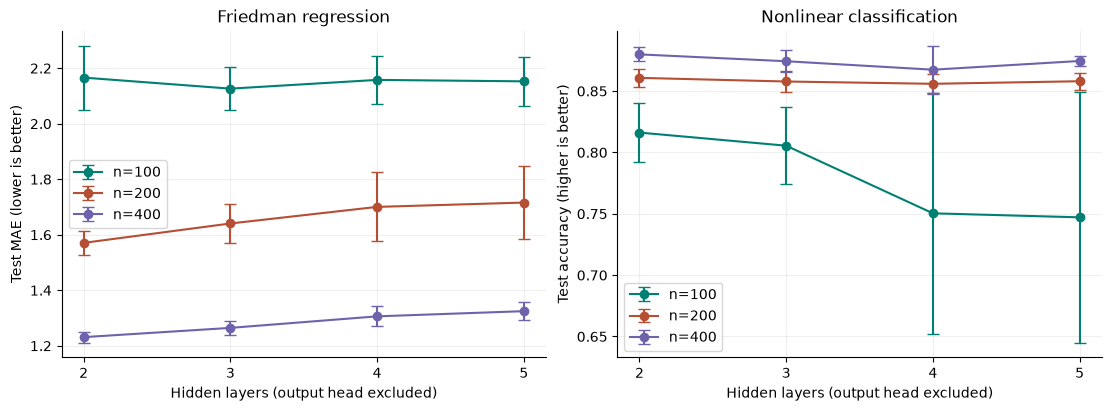

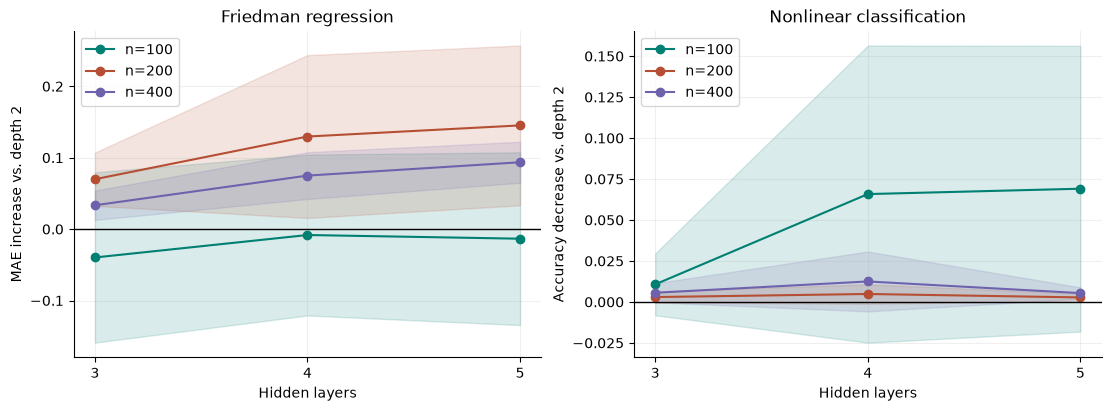

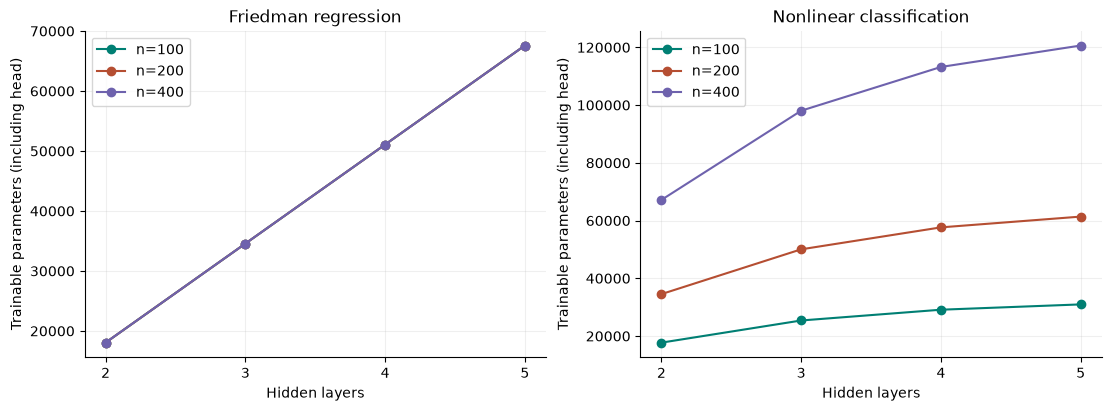


Friedman regression — mean test MAE
     n     depth 2     depth 3     depth 4     depth 5
   100      2.1661      2.1263      2.1578      2.1526
   200      1.5707      1.6406      1.7004      1.7159
   400      1.2311      1.2645      1.3061      1.3247

Nonlinear classification — mean test accuracy
     n     depth 2     depth 3     depth 4     depth 5
   100      0.8162      0.8055      0.7504      0.7471
   200      0.8608      0.8578      0.8559      0.8580
   400      0.8799      0.8743      0.8674      0.8745
Results: results/group57/20261118-060318-613937


In [5]:
def mean_ci(values):
    a = np.asarray(values, dtype=float)
    assert len(a) == len(SEEDS) and np.isfinite(a).all()
    center = float(a.mean())
    half = float(t.ppf(0.975, len(a)-1)*a.std(ddof=1)/np.sqrt(len(a)))
    return center, center-half, center+half

summary = []
for task in TASKS:
    for n in TRAIN_SIZES:
        for depth in DEPTHS:
            selected = [r for r in rows if r["task"] == task and r["n"] == n and r["depth"] == depth]
            for metric in ("test_score", "optimization_score", "generalization_gap", "epochs", "fit_seconds"):
                mean, lo, hi = mean_ci([r[metric] for r in selected])
                summary.append(dict(task=task, n=n, depth=depth, metric=metric,
                                    mean=mean, ci_low=lo, ci_high=hi, seeds=len(selected)))
write_csv(OUT / "summary.csv", summary)

lookup = {(r["task"], r["n"], r["seed"], r["depth"]): r for r in rows}
paired = []
for task in TASKS:
    for n in TRAIN_SIZES:
        for depth in DEPTHS[1:]:
            deltas = [(lookup[task, n, s, depth]["test_score"]-lookup[task, n, s, 2]["test_score"])
                      * (1 if task == TASKS[0] else -1) for s in SEEDS]
            mean, lo, hi = mean_ci(deltas)
            paired.append(dict(task=task, n=n, depth=depth, degradation=mean,
                               ci_low=lo, ci_high=hi, seeds=len(SEEDS)))
write_csv(OUT / "paired_degradation.csv", paired)

capacity = []
for task in TASKS:
    for n in TRAIN_SIZES:
        for depth in DEPTHS:
            selected = [r for r in rows if r["task"] == task and r["n"] == n and r["depth"] == depth]
            assert len({r["parameters"] for r in selected}) == 1
            assert len({r["widths"] for r in selected}) == 1
            capacity.append(dict(task=task, n=n, depth=depth, widths=selected[0]["widths"],
                                 parameters=selected[0]["parameters"],
                                 mean_epochs=float(np.mean([r["epochs"] for r in selected])),
                                 epoch_cap_hits=sum(r["hit_epoch_cap"] for r in selected)))
write_csv(OUT / "capacity.csv", capacity)

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
colors = dict(zip(TRAIN_SIZES, ("#007f73", "#b54e32", "#6e62ad")))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, task in zip(axes, TASKS):
    for n in TRAIN_SIZES:
        vals = [r for r in summary if r["task"] == task and r["n"] == n and r["metric"] == "test_score"]
        mean = np.array([r["mean"] for r in vals])
        ax.errorbar(DEPTHS, mean, yerr=[mean-[r["ci_low"] for r in vals],
                                       np.array([r["ci_high"] for r in vals])-mean],
                    fmt="o-", capsize=4, color=colors[n], label=f"n={n}")
    ax.set(xticks=DEPTHS, xlabel="Hidden layers (output head excluded)", title=task,
           ylabel="Test MAE (lower is better)" if task == TASKS[0] else "Test accuracy (higher is better)")
    ax.grid(alpha=0.2); ax.legend()
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"depth_performance.{ext}", dpi=180)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, task in zip(axes, TASKS):
    for n in TRAIN_SIZES:
        vals = [r for r in paired if r["task"] == task and r["n"] == n]
        ax.plot(DEPTHS[1:], [r["degradation"] for r in vals], "o-", label=f"n={n}", color=colors[n])
        ax.fill_between(DEPTHS[1:], [r["ci_low"] for r in vals], [r["ci_high"] for r in vals],
                        alpha=0.15, color=colors[n])
    ax.axhline(0, color="black", lw=1)
    ax.set(xticks=DEPTHS[1:], xlabel="Hidden layers", title=task,
           ylabel="MAE increase vs. depth 2" if task == TASKS[0] else "Accuracy decrease vs. depth 2")
    ax.grid(alpha=0.2); ax.legend()
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"paired_depth_degradation.{ext}", dpi=180)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, task in zip(axes, TASKS):
    for n in TRAIN_SIZES:
        vals = [r for r in capacity if r["task"] == task and r["n"] == n]
        ax.plot(DEPTHS, [r["parameters"] for r in vals], "o-", color=colors[n], label=f"n={n}")
    ax.set(xticks=DEPTHS, xlabel="Hidden layers", ylabel="Trainable parameters (including head)", title=task)
    ax.grid(alpha=0.2); ax.legend()
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"depth_capacity.{ext}", dpi=180)
plt.show()

for task in TASKS:
    print("\n" + task + (" — mean test MAE" if task == TASKS[0] else " — mean test accuracy"))
    print(f"{'n':>6}" + "".join(f"{'depth '+str(d):>12}" for d in DEPTHS))
    for n in TRAIN_SIZES:
        vals = [next(r["mean"] for r in summary if r["task"] == task and r["n"] == n
                     and r["depth"] == depth and r["metric"] == "test_score") for depth in DEPTHS]
        print(f"{n:6d}" + "".join(f"{v:12.4f}" for v in vals))
print("Results:", OUT)

## Interpretation

This is an ablation of **the native SmallMLP width rules and training recipe**. Added layers also change parameter count, repeated dropout, and optimization difficulty. A larger test error does not by itself identify overfitting: inspect optimization metrics and stopping behavior too. A parameter-matched width comparison and training-budget sensitivity would be separate controls.

The experiment can support statements about the tested tasks and settings. It cannot prove universal failure of deep learning below 500 samples, nor that scaling width is always preferable. Report improved and inconclusive cases alongside deterioration. Exact reproducibility across different package versions or hardware is not guaranteed.

References: [SmallMLP implementation](https://github.com/nsdmlk/SmallMLP), [PyTorch reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html), [joblib parallel configuration](https://joblib.readthedocs.io/en/stable/generated/joblib.parallel_config.html).